In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones normal y tope (semanas) y coste unitario de reducción (k€/semana) se adjunta. Las actividades con CUR infinito no pueden acelerarse.

In [3]:
pregunta_1 = "1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  "
pregunta_2 = "2. La actividad crítica más barata de acelerar es A. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  "
pregunta_3 = "3. Compruébelo: acorte A una semana y recalcule la duración.  "
pregunta_4 = "4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  

2. La actividad crítica más barata de acelerar es A. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  

3. Compruébelo: acorte A una semana y recalcule la duración.  

4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr   
    ('A'     , '---'      , 6       , 3           , 1     ),
    ('B'     , '---'      , 6       , 5           , 9     ),
    ('C'     , 'A,B'      , 3       , 1           , 4     ),
    ('D'     , 'C'        , 2       , 2           , np.inf),
    ('E'     , 'D'        , 5       , 5           , np.inf),
    ('F'     , 'E'        , 3       , 2           , 5     ),
    ('G'     , 'F'        , 4       , 4           , np.inf),
    ('H'     , 'E'        , 6       , 3           , 6     ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr
activity,,,,
A,---,6,3,1.0
B,---,6,5,9.0
C,"A,B",3,1,4.0
D,C,2,2,inf
E,D,5,5,inf
F,E,3,2,5.0
G,F,4,4,inf
H,E,6,3,6.0


# Resolución

In [5]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Determine la duración del proyecto y sus rutas críticas. ¿Qué actividades son comunes a todas ellas?  

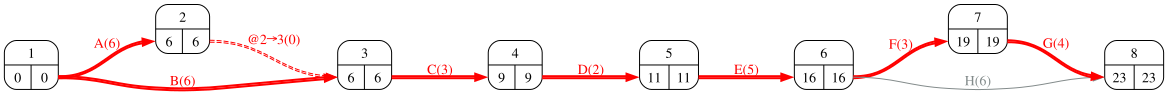

In [7]:
#| fig-cap: "Grafo PERT con las duraciones normales y las rutas críticas"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [8]:
duracion_normal = proyecto.duration(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
comunes = set.intersection(*[set(a) for a in rutas_criticas.values()])
Markdown(f'Duración {duracion_normal} semanas con {len(rutas_criticas)} rutas críticas; actividades comunes a todas: {", ".join(sorted(comunes)) or "ninguna"}.')

Route_1: A - C - D - E - F - G
Route_3: B - C - D - E - F - G


Duración 23 semanas con 2 rutas críticas; actividades comunes a todas: C, D, E, F, G.

## Apartado 2

In [9]:
display(Markdown(pregunta_2))

2. La actividad crítica más barata de acelerar es A. Un compañero propone acortarla una semana para reducir el proyecto una semana. Prediga, sin calcular, si funcionará.  

No funcionará: A está en una sola de las rutas críticas. Al acortarla, esa ruta se acorta, pero la otra sigue midiendo lo mismo y el proyecto también. Para reducir el proyecto hay que acortar *todas* las rutas críticas a la vez: una actividad común, o una actividad de cada ruta.

## Apartado 3

In [10]:
display(Markdown(pregunta_3))

3. Compruébelo: acorte A una semana y recalcule la duración.  

In [11]:
barata = 'A'
d1 = datos_proyecto['duration'].copy(); d1[barata] -= 1
Markdown(f'Acortando {barata} una semana la duración del proyecto es {proyecto.duration(d1)} semanas (antes {duracion_normal}): '
         f'se han gastado {datos_proyecto.loc[barata, "ucr"]:.0f} k€ para nada; la ruta {[r for r, a in rutas_criticas.items() if barata not in a][0]} sigue siendo crítica.')

Acortando A una semana la duración del proyecto es 23 semanas (antes 23): se han gastado 1 k€ para nada; la ruta Route_3 sigue siendo crítica.

## Apartado 4

In [12]:
display(Markdown(pregunta_4))

4. Aplique el algoritmo de Ackoff-Sasieni para reducir el proyecto dos semanas con mínimo coste y explique por qué en cada paso elige lo que elige (actividad común frente a pareja de actividades).  

In [13]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen_restante = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=2, report=False)
tabla_ackoff

,A,B,C,D,E,F,G,H,0,1,2
Route_1,1.0,,4.0,inf,inf,5.0,inf,,23.0,22.0,21.0
Route_2,1.0,,4.0,inf,inf,,,6.0,22.0,21.0,20.0
Route_3,,9.0,4.0,inf,inf,5.0,inf,,23.0,22.0,21.0
Route_4,,9.0,4.0,inf,inf,,,6.0,22.0,21.0,20.0
0,3.0,1.0,2.0,0.0,0.0,1.0,0.0,3.0,,,
1,3.0,1.0,1.0,0.0,0.0,1.0,0.0,3.0,,,
2,3.0,1.0,0.0,0.0,0.0,1.0,0.0,3.0,,,


In [14]:
resumen = pd.DataFrame({'actividades acortadas': [', '.join(acts) for acts in pasos.values()],
                        'coste del paso': [sum(datos_proyecto.loc[acts, 'ucr']) for acts in pasos.values()]},
                       index=pd.Index(range(1, len(pasos) + 1), name='paso'))
resumen

,actividades acortadas,coste del paso
paso,,
1,C,4.0
2,C,4.0


In [15]:
mas_barata_comun = min(comunes, key=lambda a: datos_proyecto.loc[a, 'ucr']) if comunes else None
pareja = sorted(set(a for r, acts in rutas_criticas.items() for a in acts) - comunes, key=lambda a: datos_proyecto.loc[a, 'ucr'])
Markdown(f'''En cada paso el algoritmo compara el coste de la actividad común más barata ({mas_barata_comun}: {datos_proyecto.loc[mas_barata_comun, "ucr"]:.0f} k€) con el de la pareja más barata que cubre las dos rutas, y elige la opción de menor coste *que reduzca todas las rutas críticas*. {barata} sola nunca es candidata, por barata que sea, salvo emparejada con una actividad de la otra ruta.''')

En cada paso el algoritmo compara el coste de la actividad común más barata (C: 4 k€) con el de la pareja más barata que cubre las dos rutas, y elige la opción de menor coste *que reduzca todas las rutas críticas*. A sola nunca es candidata, por barata que sea, salvo emparejada con una actividad de la otra ruta.

In [16]:
Markdown(f'Duración final {proyecto.duration(duraciones_reducidas)} semanas, sobrecoste total {resumen["coste del paso"].sum():.0f} k€.')

Duración final 21 semanas, sobrecoste total 8 k€.